# Convert to Dataframe Using Multiprocessing Pool

Authors: TDM Studio Team and Naomi Baes

#### Background Context
**Multiprocessing** is a useful python package that enables users to utilize multiple processors on a given machine for more efficient progress. The Pool object allows the exploitation of data parallelism by distributing the work across a pool of processes running the same function. This greatly improves the speed at which the work is done, reducing overall runtime.

Multiprocessing is mainly preferred when calling functions on larger sets of data expressing data parallelism. Data parallelism is the concept of breaking a set of data into smaller sets, which is then processed on multiple processes applying the same function without communicating with each other. Joining the output of these processes should produce the same result as if one process had applied the function to the entire dataset.

#### Script Purpose
This script is the multiprocessing variation of the **Convert to Dataframe** script. In this sample script, we will demonstrate the use of Multiprocessing Pool in parsing large numbers of XML files. We will create the function for parsing, create a pool object, and then call the function using that pool object to run via multiprocessing.

#### Expected Runtime and Sample Size
Mileage will vary depending on document size and resources available. On the standard notebook instance with 4 cores, expect around 8 minutes of runtime to process 53k New York Times articles and around 2 minutes of runtime to process 5k dissertations. The beginning input size is set to the corpus `SAMPLEDATA`, which includes around 53k articles.

## Import Libraries

In [1]:
# Libraries for parsing data
from lxml import etree
from bs4 import BeautifulSoup
import pandas as pd
import os

# Libraries for multiprocessing
import multiprocessing as mp
from multiprocessing import Pool

In [80]:
#! pip install bs4
#!pip install lxml

## Load Data

In [2]:
# Set corpus to the folder of files you want to use
corpus = '/home/ec2-user/SageMaker/data/ADHD_ADD_only_candidates/'

# Read in files
input_files = os.listdir(corpus)

print("Loaded", len(input_files), "documents.")

Loaded 932 documents.


## Specify Output File

Define the `output_file` variable to the desired save location and file name. This variable will be used at the end of the script to save the processed data.

In [3]:
# Modify output_file to desired save name
output_file = 'output/ADHD-ADD_US_newsstream.csv'

In [4]:
pwd

'/home/ec2-user/SageMaker/ADHD_conceptual_change/0_corpus_processing'

In [5]:
# Define the folder name
output_folder = "output"

# Create the folder if it doesn't exist
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"Created folder: '{output_folder}'")
else:    
    print(f"Folder already exists: '{output_folder}'")

Folder already exists: 'output'


## Define Functions

In [6]:
# Function to strip html tags from text portion
def strip_html_tags(text):
    stripped = BeautifulSoup(text).get_text().replace('\n', ' ').replace('\\', '').strip()
    return stripped

In [7]:
# Retrieve metadata from XML document
def getxmlcontent(corpus, file, strip_html=True):
    try:
        tree = etree.parse(corpus + file)
        root = tree.getroot()

        if root.find('.//GOID') is not None:
            goid = root.find('.//GOID').text
        else:
            goid = None

        if root.find('.//Title') is not None:
            title = root.find('.//Title').text
        else:
            title = None

        if root.find('.//NumericDate') is not None:
            date = root.find('.//NumericDate').text
        else:
            date = None
            
        if root.find('.//PublisherName') is not None:
            publisher = root.find('.//PublisherName').text
        else:
            publisher = None

        if root.find('.//FullText') is not None:
            text = root.find('.//FullText').text

        elif root.find('.//HiddenText') is not None:
            text = root.find('.//HiddenText').text

        elif root.find('.//Text') is not None:
            text = root.find('.//Text').text

        else:
            text = None

        # Strip html from text portion
        if text is not None and strip_html == True:
            text = strip_html_tags(text)
            
        if root.find('.//PubFrosting/SourceType') is not None:
            sourcetype = root.find('.//PubFrosting/SourceType').text
        else:
            sourcetype = None
        
        if root.find('.//PubFrosting/publisher/PublisherAddress/Province') is not None:
            pubprovince = root.find('.//PubFrosting/publisher/PublisherAddress/Province').text
        else:
            pubprovince = None
    
    except Exception as e:
        print(f"Error while parsing file {file}: {e}")
    
    return goid, title, date, publisher, text, sourcetype, pubprovince

In [8]:
# Function to make lists out of parsed data--on single document scale for multiprocessing
def make_lists(file):
    
    goid, title, date, publisher, text, sourcetype, pubprovince = getxmlcontent(corpus, file, strip_html=True)
    
    return goid, title, text, date, publisher, sourcetype, pubprovince

## Run Multiprocessing to parse XML files

In [9]:
# Test function on single document
make_lists(input_files[1])

('284473569',
 'Date Book',
 None,
 '1993-04-14',
 'Grand Rapids Press',
 'Newspapers',
 'MI')

In [14]:
from multiprocessing import Pool, cpu_count

# Leave one CPU core free, but always use at least one process
num_processes = max(1, cpu_count() - 1)

try:
    with Pool(processes=num_processes) as pool:
        processed_lists = pool.map(make_lists, input_files)

    print(f"Successfully processed {len(processed_lists)} files.")

except Exception as e:
    print(f"Error while processing documents: {e}")
    raise

Successfully processed 932 files.


In [15]:
# Transform processed data into a dataframe
df = pd.DataFrame(processed_lists, columns=['GOID', 'Title', 'Text', 'Date', 'Publisher', 'SourceType', 'PublisherProvince'])

In [16]:
# View dataframe
df

,GOID,Title,Text,Date,Publisher,SourceType,PublisherProvince
0,423526484,CHILDREN'S CARNIVAL,None,1994-05-22,"Richmond Newspapers, Incorporated",Newspapers,VA
1,284473569,Date Book,None,1993-04-14,Grand Rapids Press,Newspapers,MI
2,281799921,Master of Magic The `Wizard of Oxnard' uses ol...,"With parents and younger siblings in tow, stud...",1992-08-13,Los Angeles Times Communications LLC,Newspapers,CA
3,271500306,"Rockets wear the crown, but contention runs deep",None,1994-11-01,"The San Diego Union-Tribune, LLC.",Newspapers,CA
4,259641468,Dinner launches help group,None,1995-03-18,Kansas City Star Company,Newspapers,MO
...,...,...,...,...,...,...,...
927,270587867,HEALTH BRIEFS,Hospital offers free screening for hip pain En...,1998-09-10,Halifax Media Group,Newspapers,FL
928,291797602,THE PLAIN DEALER PLAYER OF THE WEEK,None,1997-05-22,Cleveland Plain Dealer,Newspapers,OH
929,388425257,CRIME BILL WOULD ATTACK RIGHTS,None,1994-08-20,Virginian Pilot,Newspapers,VA
930,422514979,Why are we putting down Rickey simply for bein...,None,1991-05-03,"The San Diego Union-Tribune, LLC.",Newspapers,CA


In [17]:
# Ensure 'Date' column is in datetime format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extract 4-digit year and create new column 'year'
df['year'] = df['Date'].dt.year

df.columns = ['id','title', 'text','date','publisher','source_type', 'pub_province','year']

# Preview the updated DataFrame
df.head()

,id,title,text,date,publisher,source_type,pub_province,year
0,423526484,CHILDREN'S CARNIVAL,None,1994-05-22,"Richmond Newspapers, Incorporated",Newspapers,VA,1994
1,284473569,Date Book,None,1993-04-14,Grand Rapids Press,Newspapers,MI,1993
2,281799921,Master of Magic The `Wizard of Oxnard' uses ol...,"With parents and younger siblings in tow, stud...",1992-08-13,Los Angeles Times Communications LLC,Newspapers,CA,1992
3,271500306,"Rockets wear the crown, but contention runs deep",None,1994-11-01,"The San Diego Union-Tribune, LLC.",Newspapers,CA,1994
4,259641468,Dinner launches help group,None,1995-03-18,Kansas City Star Company,Newspapers,MO,1995


## Inspect CSV

NAs

In [18]:
df.isna().sum()

id                0
title             0
text            408
date              0
publisher         0
source_type       0
pub_province      6
year              0
dtype: int64

In [19]:
len(df) # get total # of rows before dropping NA rows

932

In [20]:
df = df.dropna(subset=['text']) # drop rows where 'Text' column is missing Nan

In [21]:
len(df) # get total # of rows after dropping NA rows

524

In [23]:
df.isna().sum()

id              0
title           0
text            0
date            0
publisher       0
source_type     0
pub_province    1
year            0
dtype: int64

In [24]:
# Check that all article ids are unique
df['id'].is_unique

True

## Descriptive Statistics

In [25]:
desc_output_folder = 'output/descriptives'

### Text counts

In [27]:
# count total entries per year (before removing missing 'text' entries)
row_counts_byyear = df.groupby('year').size().reset_index(name='count')

print(row_counts_byyear)

# save to csv
output_path = os.path.join(desc_output_folder, 'row_counts_byyear-CHECK.csv')
row_counts_byyear.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

   year  count
0  1990     36
1  1991     27
2  1992     27
3  1993     40
4  1994     40
5  1995     45
6  1996     56
7  1997     59
8  1998     71
9  1999    123
Saved to output/descriptives/row_counts_byyear-CHECK.csv


In [28]:
# count non-missing 'text' entries per year
text_counts_byyear = df.groupby('year')['text'].count().reset_index(name='count')

print(text_counts_byyear)

# save to csv
output_path = os.path.join(desc_output_folder, 'text_counts_byyear-CHECK.csv')
text_counts_byyear.to_csv(output_path, index=False)

print(f"Saved tp {output_path}")

   year  count
0  1990     36
1  1991     27
2  1992     27
3  1993     40
4  1994     40
5  1995     45
6  1996     56
7  1997     59
8  1998     71
9  1999    123
Saved tp output/descriptives/text_counts_byyear-CHECK.csv


## Publication type counts

In [104]:
# --------- Per-year summary ---------
source_type_stats_by_year = df.groupby('year')['source_type'].agg(
    unique_count='nunique',
    source_Type_list=lambda x: sorted(x.dropna().unique().tolist())
).reset_index()

# Save per-year file
yearly_output_path = os.path.join(desc_output_folder, 'source_type_counts_byyear.csv')
source_type_stats_by_year.to_csv(yearly_output_path, index=False)

print(f"Saved per-year province summary to {yearly_output_path}")


Saved per-year province summary to output/descriptives/source_type_counts_byyear.csv


In [29]:
# --------- Overall total summary for source_type ---------
source_type_counts = df['source_type'].dropna().value_counts().sort_index()

# Save summary with counts
total_output_path = os.path.join(desc_output_folder, 'source_type_total_summary-CHECK.txt')

with open(total_output_path, 'w') as f:
    f.write(f"Total unique source types: {len(source_type_counts)}\n\n")
    f.write("Source type counts:\n")
    for source_type, count in source_type_counts.items():
        f.write(f"{source_type}: {count}\n")

print(f"Saved overall source_type summary to {total_output_path}")

Saved overall source_type summary to output/descriptives/source_type_total_summary-CHECK.txt


## Province counts

In [30]:
# --------- Per-year summary ---------
province_stats_by_year = df.groupby('year')['pub_province'].agg(
    unique_count='nunique',
    province_list=lambda x: sorted(x.dropna().unique().tolist())
).reset_index()

# Save per-year file
yearly_output_path = os.path.join(desc_output_folder, 'province_counts_byyear-CHECK.csv')
province_stats_by_year.to_csv(yearly_output_path, index=False)

#print(province_stats_by_year)
print(f"Saved per-year province summary to {yearly_output_path}")


Saved per-year province summary to output/descriptives/province_counts_byyear-CHECK.csv


In [31]:
# --------- Overall total summary ---------
all_provinces = df['pub_province'].dropna().unique()
all_provinces_sorted = sorted(all_provinces)
total_unique_provinces = len(all_provinces_sorted)

# Save total summary to separate file
total_output_path = os.path.join(desc_output_folder, 'province_total_summary-CHECK.txt')
with open(total_output_path, 'w') as f:
    f.write(f"Total unique provinces: {total_unique_provinces}\n")
    f.write("Province list:\n")
    f.write(", ".join(all_provinces_sorted))

print(all_provinces_sorted)
print(f"Saved overall province summary to {total_output_path}")

['CA', 'CO', 'DC', 'FL', 'GA', 'IL', 'MA', 'MD', 'ME', 'MN', 'MO', 'NE', 'NJ', 'NM', 'NV', 'NY', 'New York', 'PA', 'TX', 'UT', 'VA', 'WA', 'WI', 'WV']
Saved overall province summary to output/descriptives/province_total_summary-CHECK.txt


### publisher count

In [32]:
# --------- Per-year summary ---------
publisher_stats_by_year = df.groupby('year')['publisher'].agg(
    unique_count='nunique',
    province_list=lambda x: sorted(x.dropna().unique().tolist())
).reset_index()

# Save per-year file
yearly_output_path = os.path.join(desc_output_folder, 'publisher_counts_byyear-CHECK.csv')
publisher_stats_by_year.to_csv(yearly_output_path, index=False)

#print(province_stats_by_year)
print(f"Saved per-year publisher summary to {yearly_output_path}")

Saved per-year publisher summary to output/descriptives/publisher_counts_byyear-CHECK.csv


In [33]:
# --------- Overall total summary ---------
all_publisher = df['publisher'].dropna().unique()
all_publisher_sorted = sorted(all_publisher)
total_unique_publisher = len(all_publisher_sorted)

# Save total summary to separate file
total_output_path = os.path.join(desc_output_folder, 'publisher_total_summary-CHECK.txt')
with open(total_output_path, 'w') as f:
    f.write(f"Total unique publisher: {total_unique_publisher}\n")
    f.write("Publisher list:\n")
    f.write(", ".join(all_publisher_sorted))

print(all_publisher_sorted)

print(f"Saved overall publisher summary to {total_output_path}")

['Afro - American Company of Baltimore City', 'Atlanta Journal Constitution, LLC', 'Baltimore Sun', 'Bangor Daily News', 'Boston Globe Media Partners, LLC', 'BridgeTower Media Holding Company', 'Business Wire', 'Charleston Newspapers', 'Clinton Reilly Communications, Inc.', 'Columbian Publishing Company', 'Cowles Publishing Company, d/b/a The Spokesman-Review', 'Daily Herald', 'Dow Jones & Company Inc.', 'Freedom Newspapers, Inc.', 'Gannett Media Corp', 'GateHouse Media, Inc.', 'Halifax Media Group', 'Hampton Roads Chamber of Commerce', 'ImpreMedia Operating Company, LLC', 'Jewish Exponent', 'Journal Sentinel Inc.', 'LNP Media Group Inc.', 'Las Vegas Review - Journal', 'Lee Enterprises, Inc.', 'Los Angeles Newspaper Group', 'Los Angeles Sentinel', 'Los Angeles Times Communications LLC', 'Madison Newspapers, Inc.', 'NPR', 'New York Amsterdam News', 'New York Times Company', 'Newsday LLC', 'PR Newswire Association LLC', 'Pantagraph Publishing Co.', 'Philadelphia Media Network (Newspapers

In [34]:
# Count of unique publisher
publisher_counts = df['publisher'].value_counts(dropna=True)

# Print each publisher with its count
#print(publisher_counts)

# Temporarily disable row truncation in pandas
with pd.option_context('display.max_rows', None):
    print(publisher_counts)
    
# Save to a file
counts_output_path = os.path.join(desc_output_folder, 'publisher_counts-CHECK.txt')
with open(counts_output_path, 'w') as f:
    f.write("Publisher Counts:\n")
    f.write(publisher_counts.to_string(max_rows=None)) # This ensures all rows are printed

print(f"Saved publisher counts summary to {counts_output_path}")

publisher
Tribune Publishing Company, LLC                                         102
Gannett Media Corp                                                       57
New York Times Company                                                   48
Newsday LLC                                                              32
Atlanta Journal Constitution, LLC                                        24
Halifax Media Group                                                      23
GateHouse Media, Inc.                                                    21
Business Wire                                                            18
Pulitzer, Inc.                                                           16
BridgeTower Media Holding Company                                        15
Pantagraph Publishing Co.                                                14
Times Publishing Company                                                 13
PR Newswire Association LLC                                              11
Da

### plot

In [111]:
#!pip install seaborn


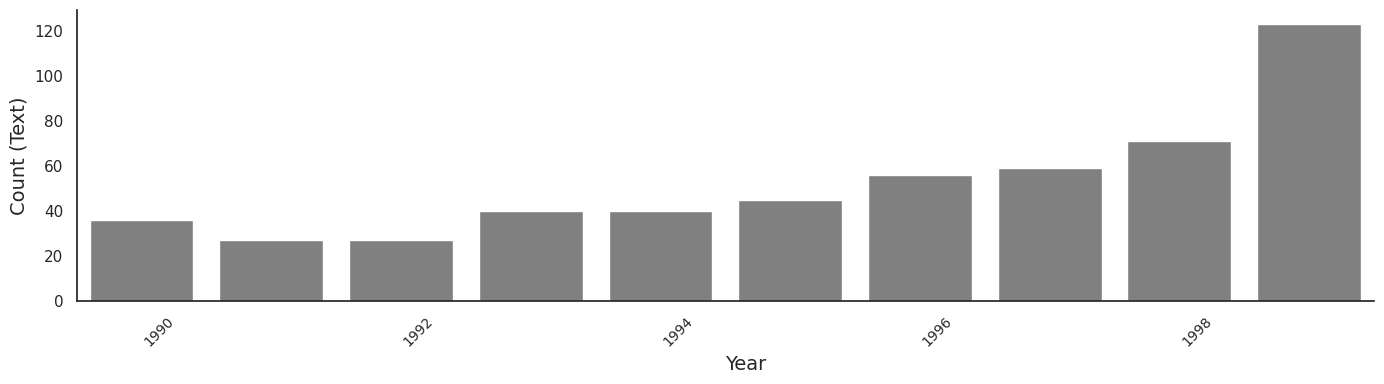

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Load CSV
text_counts_df = pd.read_csv(output_path)

# Keep year as str for Seaborn barplot
text_counts_df['year_str'] = text_counts_df['year'].astype(str)
text_counts_df['count'] = text_counts_df['count'].astype(int)

# Get range for ticks using numeric version
year_min = text_counts_df['year'].min()
year_max = text_counts_df['year'].max()

# Set classic Seaborn theme
sns.set_theme(style="white")

# Plot
plt.figure(figsize=(14, 4))
sns.barplot(data=text_counts_df, x='year_str', y='count', color='grey')

plt.xlabel('Year', fontsize=14, ha='left')
plt.ylabel('Count (Text)', fontsize=14)

plt.xticks(
    ticks=range(0, len(text_counts_df), 2),  # every 2nd tick index
    labels=text_counts_df['year_str'][::2],  # corresponding year labels
    rotation=45,
    ha='left',
    fontsize=10
)

sns.despine()
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(desc_output_folder, "text_count_byyear_classic_seaborn-CHECK.png"))
plt.close()

In [36]:
print("--- Dataframe ID Column Check ---")
print(f"ID Column Data Type: {df['id'].dtype}")
print(f"Number of Unique IDs: {df['id'].nunique()}")
print(f"Number of rows with NaNs in 'id': {df['id'].isna().sum()}")

# Replace the ID with the one that gave you the KeyError
trouble_id = 1507626216
print(f"Trouble ID found in df['id'].values: {trouble_id in df['id'].values}")

# This will check for the ID as an integer, float, and string
print(f"Trouble ID as int: {int(trouble_id) in df['id'].values}")
print(f"Trouble ID as float: {float(trouble_id) in df['id'].values}")
print(f"Trouble ID as string: {str(trouble_id) in df['id'].values}")
print("-----------------------------------")

--- Dataframe ID Column Check ---
ID Column Data Type: object
Number of Unique IDs: 524
Number of rows with NaNs in 'id': 0
Trouble ID found in df['id'].values: False
Trouble ID as int: False
Trouble ID as float: False
Trouble ID as string: False
-----------------------------------


In [37]:
df

,id,title,text,date,publisher,source_type,pub_province,year
2,281799921,Master of Magic The `Wizard of Oxnard' uses ol...,"With parents and younger siblings in tow, stud...",1992-08-13,Los Angeles Times Communications LLC,Newspapers,CA,1992
7,911552820,CALENDAR,"SUPPORT *A Sporting Chance, recreational oppo...",1999-01-31,Gannett Media Corp,Newspapers,VA,1999
8,388835956,PAID OBITUARIES,"AICHINO - Arnold, 95, of Hallandale died Octob...",1993-10-05,"Tribune Publishing Company, LLC",Newspapers,IL,1993
9,429456908,THEATER; A Bittersweet Homecoming for Mariette...,"MARIETTE HARTLEY'S opening in ""The Sisters Ros...",1994-02-06,New York Times Company,Newspapers,NY,1994
10,259338975,FEDERAL TAX LIENS,FEDERAL TAX LIENS Received 1/11/95 23 - ...,1995-01-13,BridgeTower Media Holding Company,Newspapers,MN,1995
...,...,...,...,...,...,...,...,...
918,404305206,REFUSE TO ABUSE NATIONAL COMPAIGN INCLUDES FOR...,HIGH SCHOOL O'FALLON Sandwiched between two...,1997-02-25,"Pulitzer, Inc.",Newspapers,MO,1997
920,890364394,OBITUARIES,OBITUARIES WILLIAM ARMET PORT ST. LUCIE -- W...,1999-01-08,Gannett Media Corp,Newspapers,VA,1999
921,260394430,"[Headline Missing] Lindberg, Scott T.","Lindberg, Scott T. Tues., May 14, 1996, a...",1996-05-16,Journal Sentinel Inc.,Newspapers,WI,1996
926,437081708,public32240297.sgml,"Y bjbjWW "" '= '= ] n n n n n n n ...",1999-12-04,Gannett Media Corp,Newspapers,VA,1999


In [40]:
#Normalisation functions for duplicate filtering

import os
import re
import pandas as pd
import networkx as nx
from datasketch import MinHash, MinHashLSH

# ----------------------
# Normalize + Shingle
# ----------------------
def normalize(text):
    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^\w\s]', '', text)
    return text.strip()

def get_shingles(text, k=5):
    words = normalize(text).split()
    return set([' '.join(words[i:i+k]) for i in range(len(words) - k + 1)])

def jaccard_sim(text1, text2, k=5):
    s1 = get_shingles(text1, k)
    s2 = get_shingles(text2, k)
    return len(s1 & s2) / len(s1 | s2) if (s1 | s2) else 0

# Create output folder
output_dir = "output/duplicatefiltering-CHECK"
os.makedirs(output_dir, exist_ok=True)


In [41]:
#preparing data for filter

cleaned_file = f"{output_dir}/articles_cleaned.csv"

force = False   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(cleaned_file):
    df = pd.read_csv(cleaned_file)
    print(f"Loaded cleaned articles from {cleaned_file}")
else:
    df['id'] = df['id'].astype(str).str.strip()
    df_indexed = df.set_index('id')
    df.to_csv(cleaned_file, index=False)
    print(f"Saved cleaned articles to {cleaned_file}")


Saved cleaned articles to output/duplicatefiltering-CHECK/articles_cleaned.csv


/tmp/ipykernel_2034321/411743735.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['id'] = df['id'].astype(str).str.strip()


In [52]:
#Build Minihashes and LSH

num_perm = 256
lsh_threshold = 0.4
shingle_size = 5
validate_threshold = 0.6

#Query and Validate potential Duplicates with exact jaccard similariy on Shingles (articles grouped by year)

validated_file = f"{output_dir}/validated_duplicates.csv"

force = True   # <<<<<< Set to True to force recomputation

if not force and os.path.exists("output/duplicatefiltering-CHECK/validated_duplicates.csv"):   
    df_validated_duplicates = pd.read_csv(validated_file)
    print(f"Loaded validated duplicates from {validated_file}")
else:
    duplicate_records = []
    seen = set()

    # Process each year separately
    for year, df_year in df.groupby('year'):
        print(f"Processing year {year} with {len(df_year)} articles...")
        lsh = MinHashLSH(threshold=lsh_threshold, num_perm=num_perm)
        minhashes = {}

        # Build MinHashes and insert into LSH
        for idx, text in zip(df_year['id'], df_year['text']):
            shingles = get_shingles(text, k=shingle_size)
            m = MinHash(num_perm=num_perm)
            for sh in shingles:
                m.update(sh.encode('utf8'))
            lsh.insert(idx, m)
            minhashes[idx] = m

        # Query duplicates within the same year
        for idx, mh in minhashes.items():
            if idx in seen:
                continue
            matches = lsh.query(mh)
            for m in matches:
                if m != idx:
                    text1 = df_year.loc[df_year['id']==idx, 'text'].values[0]
                    text2 = df_year.loc[df_year['id']==m, 'text'].values[0]
                    sim = jaccard_sim(text1, text2, k=shingle_size)
                    if sim >= validate_threshold:
                        duplicate_records.append({
                            "id": idx,
                            "duplicate_id": m,
                            "publisher": df_year.loc[df_year['id']==idx, 'publisher'].values[0],
                            "duplicate_publisher": df_year.loc[df_year['id']==m, 'publisher'].values[0],
                            "year": year,
                            "jaccard": sim
                        })
            seen.update(matches)

    df_validated_duplicates = pd.DataFrame(duplicate_records)
    df_validated_duplicates.to_csv(validated_file, index=False)
    print(f"Saved validated duplicates to {validated_file}")
    
    print(df_validated_duplicates.head(20))



Processing year 1990 with 36 articles...
Processing year 1991 with 27 articles...
Processing year 1992 with 27 articles...
Processing year 1993 with 40 articles...
Processing year 1994 with 40 articles...
Processing year 1995 with 45 articles...
Processing year 1996 with 56 articles...
Processing year 1997 with 59 articles...
Processing year 1998 with 71 articles...
Processing year 1999 with 123 articles...
Saved validated duplicates to output/duplicatefiltering/validated_duplicates.csv
            id duplicate_id                          publisher  \
0    278241142    278241097                        Newsday LLC   
1    407097719    407088183    Tribune Publishing Company, LLC   
2    342670911    342639317    Tribune Publishing Company, LLC   
3    283592698    283595164    Tribune Publishing Company, LLC   
4    306468033    259898458                      Baltimore Sun   
5    429456908    429457390             New York Times Company   
6    259362442    259337580  BridgeTower Media

In [53]:
#Build Clusters for comparison

# Create output folder
output_dir = "output/duplicatefiltering-CHECK/duplicatefiltering"
os.makedirs(output_dir, exist_ok=True)
clusters_file = f"{output_dir}/articles_with_clusters.csv"

force = False   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(clusters_file):
    df_with_clusters = pd.read_csv(clusters_file)
    clusters = df_with_clusters['cluster_id'].dropna().unique().tolist()
    print(f"Loaded articles with clusters from {clusters_file}")
else:
    if not df_validated_duplicates.empty:
        G = nx.Graph()
        G.add_edges_from(df_validated_duplicates[['id', 'duplicate_id']].itertuples(index=False, name=None))
        clusters = [list(c) for c in nx.connected_components(G)]
        cluster_map = {node: i for i, comp in enumerate(clusters) for node in comp}
        df_with_clusters = df.copy()
        df_with_clusters['cluster_id'] = df_with_clusters['id'].map(cluster_map)
    else:
        clusters = []
        df_with_clusters = df.copy()
        df_with_clusters['cluster_id'] = None

    df_with_clusters.to_csv(clusters_file, index=False)
    print(f"Saved articles with clusters to {clusters_file}")
    
    print(df_with_clusters.head(20))


Saved articles with clusters to output/duplicatefiltering-CHECK/duplicatefiltering/articles_with_clusters.csv
            id                                              title  \
2    281799921  Master of Magic The `Wizard of Oxnard' uses ol...   
7    911552820                                           CALENDAR   
8    388835956                                    PAID OBITUARIES   
9    429456908  THEATER; A Bittersweet Homecoming for Mariette...   
10   259338975                                  FEDERAL TAX LIENS   
11   437240352                   Prom mementos undermine teaching   
13   270531271                              LEARN ABOUT DISORDERS   
14   253974047                                         GOOD STUFF   
15   343015542  D.D. JONES - WORK IN PROGRESS TRANSFER COMPANY...   
17   278915036                   RUNNING Ronan's Circuitous Route   
19   449778344  Society of Automotive Engineers Detroit Sectio...   
21   259362442                             CORPORATION COMMISS

In [54]:
#Deduplicate at cluster level (keeping longest article)

dedup_file = f"{output_dir}/deduplicated_articles.csv"

force = False   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(dedup_file):
    df_noduplicates = pd.read_csv(dedup_file)
    print(f"Loaded deduplicated articles from {dedup_file}")
else:
    if clusters:
        df_with_clusters['text_len'] = df_with_clusters['text'].fillna("").str.split().str.len()
        representatives = (
            df_with_clusters.dropna(subset=['cluster_id'])
            .sort_values('text_len', ascending=False)
            .groupby('cluster_id')
            .first()
            .reset_index()
        )
        df_noduplicates = pd.concat([
            representatives,
            df_with_clusters[df_with_clusters['cluster_id'].isna()]
        ])
    else:
        df_noduplicates = df.copy()

    df_noduplicates.to_csv(dedup_file, index=False)
    print(f"Saved deduplicated articles to {dedup_file}")
    
    print(df_noduplicates.head(10))


Saved deduplicated articles to output/duplicatefiltering-CHECK/duplicatefiltering/deduplicated_articles.csv
   cluster_id         id                                              title  \
0         0.0  278241142                                       QUEENS GUIDE   
1         1.0  407097719           [Headline Missing] Learn about the press   
2         2.0  342670911                             CLUB & VOLUNTEER NOTES   
3         3.0  283592698                                   Fast Track. Q&A.   
4         4.0  259898458  Bam! Pow! Sock! Woody, Mia battle it out on pa...   
5         5.0  429456908  THEATER; A Bittersweet Homecoming for Mariette...   
6         6.0  259337580                             CORPORATION COMMISSION   
7         7.0  388720818             HUMANITARIAN WORK RECEIVES RECOGNITION   
8         8.0  430708973                   Miss Tausch, Dr. Gonzalez-Molina   
9         9.0  240187887                         THEY'LL HOP TILL THEY DROP   

                      

In [55]:
#Prepare sample for inspection

sample_file = f"{output_dir}/sample_duplicates.csv"

force = True   # <<<<<< Set to True to force recomputation

if not force and os.path.exists(sample_file):
    sample_dupes = pd.read_csv(sample_file)
    print(f"Loaded sample duplicates from {sample_file}")
else:
    if not df_validated_duplicates.empty:
        sample_dupes = df_validated_duplicates.merge(
            df[['id', 'text']], left_on='id', right_on='id'
        ).rename(columns={'text': 'text_orig'})
        sample_dupes = sample_dupes.merge(
            df[['id', 'text']], left_on='duplicate_id', right_on='id'
        ).rename(columns={'text': 'text_dup'})
    else:
        sample_dupes = pd.DataFrame()

    sample_dupes.to_csv(sample_file, index=False)
    print(f"Saved sample duplicates to {sample_file}")

print("Found duplicate clusters:", len(clusters))
print("Articles after deduplication:", len(df_noduplicates))
print("Sample duplicates shape:", sample_dupes.shape)

print(sample_dupes.head(20))


Saved sample duplicates to output/duplicatefiltering-CHECK/duplicatefiltering/sample_duplicates.csv
Found duplicate clusters: 24
Articles after deduplication: 498
Sample duplicates shape: (26, 9)
          id_x duplicate_id                          publisher  \
0    278241142    278241097                        Newsday LLC   
1    407097719    407088183    Tribune Publishing Company, LLC   
2    342670911    342639317    Tribune Publishing Company, LLC   
3    283592698    283595164    Tribune Publishing Company, LLC   
4    306468033    259898458                      Baltimore Sun   
5    429456908    429457390             New York Times Company   
6    259362442    259337580  BridgeTower Media Holding Company   
7    388684226    388720818    Tribune Publishing Company, LLC   
8    430708973   2237450156             New York Times Company   
9    240207661    240187887                 Gannett Media Corp   
10   430802668   2237017282             New York Times Company   
11   2232032

In [58]:
# ----------------------------
# Borderline cases with metadata: title, publisher, and text preview
# ----------------------------

# Filter borderline similarities
lower_bound = 0.60
upper_bound = 0.65

borderline_cases = df_validated_duplicates[
    (df_validated_duplicates['jaccard'] >= lower_bound) &
    (df_validated_duplicates['jaccard'] < upper_bound)
].copy()

# --- Merge metadata for article A ---
df_a = df[['id', 'title', 'publisher', 'text']].rename(columns={
    'id': 'id_a', 'title': 'title_a', 'publisher': 'publisher_a', 'text': 'text_a'
})
borderline_cases = borderline_cases.merge(df_a, left_on='id', right_on='id_a', how='left')

# --- Merge metadata for article B ---
df_b = df[['id', 'title', 'publisher', 'text']].rename(columns={
    'id': 'id_b', 'title': 'title_b', 'publisher': 'publisher_b', 'text': 'text_b'
})
borderline_cases = borderline_cases.merge(df_b, left_on='duplicate_id', right_on='id_b', how='left')

# --- Add text previews ---
preview_len = 300
borderline_cases['preview_a'] = borderline_cases['text_a'].str.slice(0, preview_len)
borderline_cases['preview_b'] = borderline_cases['text_b'].str.slice(0, preview_len)

# --- Publisher match flag ---
borderline_cases['publisher_match'] = borderline_cases['publisher_a'] == borderline_cases['publisher_b']

# --- Title similarity function ---
def jaccard_title_sim(t1, t2):
    set1, set2 = set(str(t1).lower().split()), set(str(t2).lower().split())
    return len(set1 & set2) / len(set1 | set2) if set1 | set2 else 0

borderline_cases['title_sim'] = borderline_cases.apply(
    lambda row: jaccard_title_sim(row['title_a'], row['title_b']),
    axis=1
)

# --- Save to CSV ---
borderline_file = f"{output_dir}/borderline_cases_{lower_bound}_to_{upper_bound}_with_titles.csv"
borderline_cases.to_csv(borderline_file, index=False)
print(f"\n✅ Saved borderline cases with metadata to: {borderline_file}")

# --- Show preview ---
cols = [
    'id', 'duplicate_id', 'jaccard',
    'title_sim', 'publisher_match',
    'title_a', 'title_b', 'preview_a', 'preview_b'
]
display(borderline_cases[cols].sample(min(5, len(borderline_cases))))




✅ Saved borderline cases with metadata to: output/duplicatefiltering-CHECK/duplicatefiltering/borderline_cases_0.6_to_0.65_with_titles.csv


,id,duplicate_id,jaccard,title_sim,publisher_match,title_a,title_b,preview_a,preview_b
0,342670911,342639317,0.608579,1.0,True,CLUB & VOLUNTEER NOTES,CLUB & VOLUNTEER NOTES,FUND-RAISER AIDS PREGNANCY CENTER HAMPTON -...,RANDOLPH-MACON ALUMNI TO MEET The Peninsula...


In [59]:
df_noduplicates

,cluster_id,id,title,text,date,publisher,source_type,pub_province,year,text_len
0,0.0,278241142,QUEENS GUIDE,"ONGOING PROGRAMS THIS WEEK At 67-09 108th St.,...",1990-11-04,Newsday LLC,Newspapers,NY,1990,1122
1,1.0,407097719,[Headline Missing] Learn about the press,Learn about the press Journalism teacher...,1990-12-23,"Tribune Publishing Company, LLC",Newspapers,IL,1990,394
2,2.0,342670911,CLUB & VOLUNTEER NOTES,FUND-RAISER AIDS PREGNANCY CENTER HAMPTON -...,1993-09-30,"Tribune Publishing Company, LLC",Newspapers,IL,1993,740
3,3.0,283592698,Fast Track. Q&A.,"Additional material published Nov. 7, 1993: Co...",1993-10-31,"Tribune Publishing Company, LLC",Newspapers,IL,1993,391
4,4.0,259898458,"Bam! Pow! Sock! Woody, Mia battle it out on pa...","Illustrations. 1. & 2. Woody Allen, left, an...",1993-06-13,Las Vegas Review - Journal,Newspapers,NV,1993,399
...,...,...,...,...,...,...,...,...,...,...
914,NaN,247777469,YWCA plans safe night for teens,"No arguments, no weapons and no alcohol or dru...",1998-10-23,"Lee Enterprises, Inc.",Newspapers,NE,1998,172
918,NaN,404305206,REFUSE TO ABUSE NATIONAL COMPAIGN INCLUDES FOR...,HIGH SCHOOL O'FALLON Sandwiched between two...,1997-02-25,"Pulitzer, Inc.",Newspapers,MO,1997,688
921,NaN,260394430,"[Headline Missing] Lindberg, Scott T.","Lindberg, Scott T. Tues., May 14, 1996, a...",1996-05-16,Journal Sentinel Inc.,Newspapers,WI,1996,166
926,NaN,437081708,public32240297.sgml,"Y bjbjWW "" '= '= ] n n n n n n n ...",1999-12-04,Gannett Media Corp,Newspapers,VA,1999,540


--- Similarity Distribution Analysis ---
Total unique similar pairs found: 16
Average Jaccard Similarity: 0.8943
Median Jaccard Similarity: 1.0000
Minimum Jaccard Similarity: 0.5039
Maximum Jaccard Similarity: 1.0000


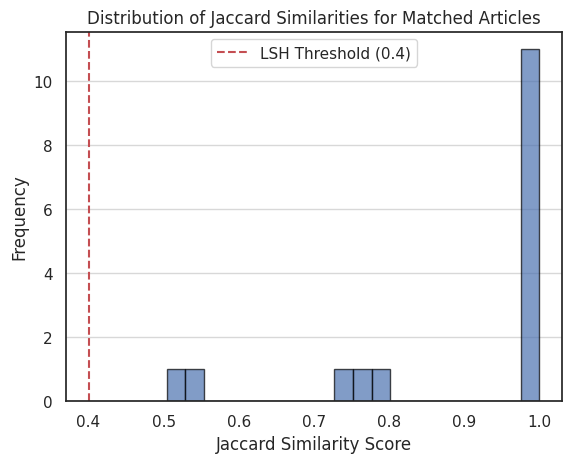

In [62]:
# ----------------------------------------------------
# 6. Analyze the Distribution of Similarities
# ----------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

# A list to store all similarity scores found
all_similarities = []
# A set to track pairs we have already compared
seen_pairs = set()

# Iterate through each article's MinHash
for idx, mh in minhashes.items():
    # Use LSH to find candidate duplicates for this article
    candidate_matches = lsh.query(mh)
    
    for m in candidate_matches:
        # **FIX:** We now keep the matched ID as a string for consistency
        # There is no need for `m = int(m)` here.
        
        # Avoid self-comparison and double-counting pairs
        if m == idx:
            continue
        # Sort the pair to ensure (1, 2) and (2, 1) are treated as the same
        # This will now work correctly since both `idx` and `m` are strings.
        pair = tuple(sorted((idx, m)))
        if pair in seen_pairs:
            continue
        
        # Get the MinHash signature of the matched article
        m_match = minhashes[m]
        
        # Calculate the Jaccard similarity and store it
        jaccard_sim = mh.jaccard(m_match)
        all_similarities.append(jaccard_sim)
        
        # Add the pair to our seen set
        seen_pairs.add(pair)

print("--- Similarity Distribution Analysis ---")
print(f"Total unique similar pairs found: {len(all_similarities)}")
if all_similarities:
    print(f"Average Jaccard Similarity: {np.mean(all_similarities):.4f}")
    print(f"Median Jaccard Similarity: {np.median(all_similarities):.4f}")
    print(f"Minimum Jaccard Similarity: {min(all_similarities):.4f}")
    print(f"Maximum Jaccard Similarity: {max(all_similarities):.4f}")

    # Plot a histogram of the similarities
    plt.hist(all_similarities, bins=20, edgecolor='black', alpha=0.7)
    plt.title('Distribution of Jaccard Similarities for Matched Articles')
    plt.xlabel('Jaccard Similarity Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.axvline(x=lsh_threshold, color='r', linestyle='--', label=f'LSH Threshold ({lsh_threshold})')
    plt.legend()
    plt.show()

Sampling 524 articles for analysis...
Starting all-pairs Jaccard calculation on the sample...
Finished. Calculated 137026 similarity scores.
--- Sample Similarity Distribution Analysis ---
Average Jaccard Similarity: 0.0003
Median Jaccard Similarity: 0.0000
Minimum Jaccard Similarity: 0.0000
Maximum Jaccard Similarity: 1.0000


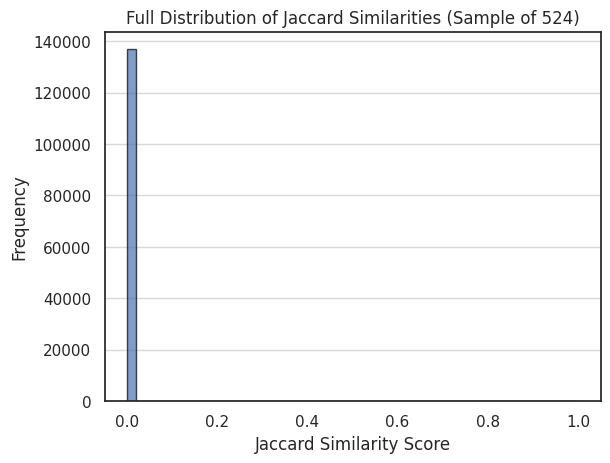

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools

# ----------------------------------------------------------------------
# 2. Sample the DataFrame and Calculate All-Pairs Similarities
# ----------------------------------------------------------------------

# Set the sample size
sample_size = 1000

# Randomly sample the DataFrame to get a representative subset
# .copy() prevents the SettingWithCopyWarning
df_sample = df.sample(n=min(sample_size, len(df))).copy()
print(f"Sampling {len(df_sample)} articles for analysis...")

# Calculate shingles for each article in the sample and store them in a dictionary
# Assumes get_shingles() is already defined
shingles_dict = {}
for idx, text in zip(df_sample['id'], df_sample['text']):
    shingles_dict[idx] = get_shingles(text)

# List to store all similarity scores
all_similarities = []

# Perform the all-pairs comparison on the sample
# itertools.combinations is a very efficient way to get every unique pair
all_pairs = itertools.combinations(shingles_dict.keys(), 2)

print("Starting all-pairs Jaccard calculation on the sample...")
for id1, id2 in all_pairs:
    shingles1 = shingles_dict[id1]
    shingles2 = shingles_dict[id2]
    
    # Calculate the Jaccard similarity: |A intersect B| / |A union B|
    try:
        jaccard_sim = len(shingles1.intersection(shingles2)) / len(shingles1.union(shingles2))
        all_similarities.append(jaccard_sim)
    except ZeroDivisionError:
        # This handles cases where two articles have no words (e.g., empty text)
        all_similarities.append(0.0)

print(f"Finished. Calculated {len(all_similarities)} similarity scores.")

# ----------------------------------------------------------------------
# 3. Analyze and Plot the Distribution
# ----------------------------------------------------------------------
if all_similarities:
    print("--- Sample Similarity Distribution Analysis ---")
    print(f"Average Jaccard Similarity: {np.mean(all_similarities):.4f}")
    print(f"Median Jaccard Similarity: {np.median(all_similarities):.4f}")
    print(f"Minimum Jaccard Similarity: {min(all_similarities):.4f}")
    print(f"Maximum Jaccard Similarity: {max(all_similarities):.4f}")

    # Plot a histogram of the similarities
    plt.hist(all_similarities, bins=50, edgecolor='black', alpha=0.7)
    plt.title(f'Full Distribution of Jaccard Similarities (Sample of {len(df_sample)})')
    plt.xlabel('Jaccard Similarity Score')
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

In [66]:
#Cosine sim of random sample of articles from deduplicated data

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# --- 1. Sample 1000 articles after deduplication ---
sampled_df = df_noduplicates.sample(n=100, random_state=42).reset_index(drop=True)

# --- 2. TF-IDF Vectorization of full text ---
vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
tfidf_matrix = vectorizer.fit_transform(sampled_df['text'])

# --- 3. Compute Cosine Similarity ---
cosine_sim = cosine_similarity(tfidf_matrix)

# --- 4. Get top N most similar pairs ---
import numpy as np

N = 50  # top N pairs to keep
similar_pairs = []

for i in range(len(sampled_df)):
    for j in range(i+1, len(sampled_df)):  # only upper triangle
        score = cosine_sim[i, j]
        similar_pairs.append((i, j, score))

# Sort by similarity score descending
similar_pairs.sort(key=lambda x: x[2], reverse=True)
top_pairs = similar_pairs[:N]

# --- 5. Build output DataFrame with metadata ---
records = []
for i, j, sim in top_pairs:
    row = {
        'id_a': sampled_df.loc[i, 'id'],
        'id_b': sampled_df.loc[j, 'id'],
        'cosine_sim': round(sim, 4),
        'title_a': sampled_df.loc[i, 'title'],
        'title_b': sampled_df.loc[j, 'title'],
        'publisher_a': sampled_df.loc[i, 'publisher'],
        'publisher_b': sampled_df.loc[j, 'publisher'],
        'year': sampled_df.loc[i, 'year'],  # assumed same
        'text_preview_a': sampled_df.loc[i, 'text'][:300],
        'text_preview_b': sampled_df.loc[j, 'text'][:300],
    }
    records.append(row)

df_top_similar = pd.DataFrame(records)

# --- 6. Display or save results ---
from IPython.display import display
display(df_top_similar)

# Optional: save to CSV
df_top_similar.to_csv("output/top_similar_article_pairs-CHECK.csv", index=False)
print("Saved top similar article pairs to output/top_similar_article_pairs-CHECK.csv")


,id_a,id_b,cosine_sim,title_a,title_b,publisher_a,publisher_b,year,text_preview_a,text_preview_b
0,278945981,278907761,0.9312,Top Of Their Class,Top Of Their Class,Newsday LLC,Newsday LLC,1996,"AT THIS TIME each year, Newsday introduces its...","AT THIS TIME each year, Newsday introduces its..."
1,394814243,394815838,0.9031,OBITUARIES,OBITUARIES,"Cowles Publishing Company, d/b/a The Spokesman...","Cowles Publishing Company, d/b/a The Spokesman...",1996,Nancy Brower Spokane Memorial service for Nanc...,"Charles Shafer St. Maries At his request, no s..."
2,436174667,436119268,0.8134,DEATH NOTICES,DEATH NOTICES,Gannett Media Corp,Gannett Media Corp,1999,"BASTA,DUSAN, July 21. Age 83. Beloved husband ...","ADRAGNA,GAETANO ""TOM"" January 28, age 73. Bel..."
3,393855495,431291863,0.8029,PICKS OF THE WEEK,"Crack a Communique, Shatter an Assumption",Gannett Media Corp,New York Times Company,1999,book and art review BOOK V D G V V D D V D...,THE CODE BOOKThe Evolution of Secrecy From Mar...
4,278883887,278738378,0.6667,PAID DEATH NOTICES,PAID DEATH NOTICES,Newsday LLC,Newsday LLC,1996,"SPOSATO - Sam, of Huntington Station, on March...","LUONGO - Ben ""Uncle Ben,"" of Valley Stream, fo..."
5,421516053,232265153,0.6501,Vanilla Ice Takes Off the Rapping; Pop music A...,The Iceman cometh back,Los Angeles Times Communications LLC,Village Voice Media Holdings LLC,1999,A shared immersion in popular culture gives mo...,"Yo V.I.P., let's kick it: Vanilla Ice has this..."
6,278883887,279213432,0.6309,PAID DEATH NOTICES,"Quotes: SCHAEFFLER - Charles Emanuel Jr., 67,",Newsday LLC,Newsday LLC,1996,"SPOSATO - Sam, of Huntington Station, on March...","Quotes: SCHAEFFLER - Charles Emanuel Jr., 67, ..."
7,436119268,278738378,0.6124,DEATH NOTICES,PAID DEATH NOTICES,Gannett Media Corp,Newsday LLC,1999,"ADRAGNA,GAETANO ""TOM"" January 28, age 73. Bel...","LUONGO - Ben ""Uncle Ben,"" of Valley Stream, fo..."
8,278883887,436174667,0.5960,PAID DEATH NOTICES,DEATH NOTICES,Newsday LLC,Gannett Media Corp,1996,"SPOSATO - Sam, of Huntington Station, on March...","BASTA,DUSAN, July 21. Age 83. Beloved husband ..."
9,278883887,436119268,0.5758,PAID DEATH NOTICES,DEATH NOTICES,Newsday LLC,Gannett Media Corp,1996,"SPOSATO - Sam, of Huntington Station, on March...","ADRAGNA,GAETANO ""TOM"" January 28, age 73. Bel..."


Saved top similar article pairs to output/top_similar_article_pairs-CHECK.csv


## Save Dataframe as CSV

Make sure to change the `output_file` variable (defined at the top of script) to desired output file name before running this cell.

In [67]:
# Save output to file
df_noduplicates.to_csv(output_file)

In [68]:
# Modify output_file to desired save name
df_noduplicates.to_csv("../input/ADHD-ADD_US_newsstream.tsv", sep="\t", index=False)

### check

In [70]:
from pathlib import Path
import pandas as pd

audit_output_path = Path(
    "../input/ADHD_ADD_only_candidates_deduplicated_1990_1999.tsv"
)

# Check the dataframe before saving
print("Dataframe shape before saving:", df_noduplicates.shape)
print("Columns:", df_noduplicates.columns.tolist())

assert 0 < len(df_noduplicates) <= 524, (
    f"Expected no more than 524 records, found {len(df_noduplicates)}"
)

# Find the year column regardless of capitalisation
year_col = next(
    (col for col in df_noduplicates.columns if col.lower() == "year"),
    None
)

assert year_col is not None, "No year column found in df_noduplicates"
assert df_noduplicates[year_col].between(1990, 1999).all(), (
    "Unexpected year detected"
)

# Save the actual deduplicated dataframe
audit_output_path.parent.mkdir(parents=True, exist_ok=True)

df_noduplicates.to_csv(
    audit_output_path,
    sep="\t",
    index=False,
    encoding="utf-8"
)

print(f"Saved to: {audit_output_path}")

Dataframe shape before saving: (498, 10)
Columns: ['cluster_id', 'id', 'title', 'text', 'date', 'publisher', 'source_type', 'pub_province', 'year', 'text_len']
Saved to: ../input/ADHD_ADD_only_candidates_deduplicated_1990_1999.tsv


In [71]:
check_df = pd.read_csv(
    audit_output_path,
    sep="\t",
    low_memory=False
)

print("Saved shape:", check_df.shape)
print("Saved columns:", check_df.columns.tolist())

check_year_col = next(
    (col for col in check_df.columns if col.lower() == "year"),
    None
)

assert check_year_col is not None, "No year column found in saved file"
assert check_df.shape == df_noduplicates.shape, (
    "Saved file shape does not match the original dataframe"
)
assert check_df[check_year_col].between(1990, 1999).all(), (
    "Unexpected year detected"
)

print(
    check_df[check_year_col]
    .value_counts()
    .sort_index()
)

Saved shape: (498, 10)
Saved columns: ['cluster_id', 'id', 'title', 'text', 'date', 'publisher', 'source_type', 'pub_province', 'year', 'text_len']
year
1990     34
1991     27
1992     27
1993     37
1994     37
1995     45
1996     55
1997     56
1998     69
1999    111
Name: count, dtype: int64


In [81]:
import re
import pandas as pd

audit_df = check_df.copy()

# Standalone A.D.D., excluding forms embedded in longer dotted acronyms
# such as M.A.D.D. or S.A.D.D.
standalone_add_pattern = re.compile(
    r"(?i)"
    r"(?<![A-Za-z]\.)"        # not immediately preceded by M. etc.
    r"(?<![A-Za-z]\.\s)"      # not preceded by M. + space
    r"(?<![A-Za-z0-9])"
    r"A\s*\.\s*D\s*\.\s*D\s*\.?"
    r"(?![A-Za-z0-9])"
)

# Longer acronyms containing A.D.D., such as M.A.D.D.
embedded_acronym_pattern = re.compile(
    r"(?i)(?:[A-Za-z]\.\s*)+A\s*\.\s*D\s*\.\s*D\s*\.?"
)

lowercase_add_pattern = re.compile(
    r"(?<![A-Za-z])add(?![A-Za-z])"
)


def classify_match(text):
    text = "" if pd.isna(text) else str(text)

    # Search for a genuine standalone A.D.D. first
    match = standalone_add_pattern.search(text)
    if match:
        return "standalone_A.D.D.", match

    # Then identify M.A.D.D., S.A.D.D., etc.
    match = embedded_acronym_pattern.search(text)
    if match:
        return "embedded_longer_acronym", match

    match = lowercase_add_pattern.search(text)
    if match:
        return "lowercase_add", match

    return "no_visible_match", None


def extract_context(text, window=350):
    text = "" if pd.isna(text) else str(text)
    _, match = classify_match(text)

    if match is None:
        return ""

    start = max(0, match.start() - window)
    end = min(len(text), match.end() + window)

    return " ".join(text[start:end].split())


audit_df["match_type"] = audit_df["text"].apply(
    lambda text: classify_match(text)[0]
)

audit_df["add_context"] = audit_df["text"].apply(extract_context)

print(audit_df["match_type"].value_counts())

print(
    pd.crosstab(
        audit_df["year"],
        audit_df["match_type"],
        margins=True
    )
)

match_type
embedded_longer_acronym    281
no_visible_match           169
standalone_A.D.D.           42
lowercase_add                6
Name: count, dtype: int64
match_type  embedded_longer_acronym  lowercase_add  no_visible_match  \
year                                                                   
1990                             18              0                15   
1991                             10              1                14   
1992                             10              1                15   
1993                             25              0                12   
1994                             23              0                13   
1995                             31              0                10   
1996                             36              1                13   
1997                             31              1                16   
1998                             31              2                27   
1999                             66            

In [83]:
for _, row in early_candidates.sort_values(["year", "id"]).iterrows():
    print("\n" + "=" * 100)
    print(f"ID: {row['id']} | Year: {row['year']}")
    print(f"Title: {row['title']}")
    print(f"Publisher: {row['publisher']}")
    print("\nContext:")
    print(row["add_context"])


ID: 268369973 | Year: 1990
Title: Vets leader asks for help in area
Publisher: GateHouse Media, Inc.

Context:
s among the children of veterans," Ms. Stout said. "It could be just something we have never heard about, but it is too much of a coincidence to ignore." CHILDREN HURTING Ms. Stout said that during a recent meeting of a Viet Vets organization, four of the six women (wives of Viet Vets) seated at her table told her teir children suffered from A.D.D. She said four officers of the national organization have children with the disorder. Ms. Stout told the 34 members of the North Quabbin Chapter of the Viet Vets organization attending the meeting that the most important recent development is the establishment of a committee to study veterans hospitals. She said the hospitals will be studied

ID: 306354708 | Year: 1991
Title: Valley Mede Shopping Center opens
Publisher: Baltimore Sun

Context:
ience center is located at 9469 Baltimore National Pike. It contains a Blockbuster Video, 

In [84]:
manual_labels = {
    268369973: (
        "valid_attention_deficit",
        "A.D.D. refers to children diagnosed with the disorder."
    ),
    306354708: (
        "unrelated_acronym",
        "A.D.D.S. is the name of a property developer."
    ),
    428241573: (
        "valid_attention_deficit",
        "A.D.D. refers to hyperactive children."
    ),
    268455901: (
        "unrelated_acronym",
        "A.D.D.A. Rlty. is a real-estate business."
    ),
    392624877: (
        "valid_attention_deficit",
        "A.D.D. seminar concerns attention deficit disorders."
    ),
}

for article_id, (classification, note) in manual_labels.items():
    mask = audit_df["id"] == article_id
    audit_df.loc[mask, "classification"] = classification
    audit_df.loc[mask, "coding_notes"] = note

display(
    audit_df.loc[
        audit_df["id"].isin(manual_labels),
        ["id", "year", "title", "classification", "coding_notes"]
    ].sort_values(["year", "id"])
)

,id,year,title,classification,coding_notes
149,268369973,1990,Vets leader asks for help in area,valid_attention_deficit,A.D.D. refers to children diagnosed with the d...
247,306354708,1991,Valley Mede Shopping Center opens,unrelated_acronym,A.D.D.S. is the name of a property developer.
408,428241573,1991,Helping Hyperactive Children Fit In,valid_attention_deficit,A.D.D. refers to hyperactive children.
155,268455901,1992,REAL ESTATE TRANSFERS,unrelated_acronym,A.D.D.A. Rlty. is a real-estate business.
80,392624877,1994,LEHIGHTON RECOGNIZED AS TREE CITY USA,valid_attention_deficit,A.D.D. seminar concerns attention deficit diso...


In [85]:
import pandas as pd

original_df = pd.read_csv(
    "../input/ADHD_US_newsstream.tsv",
    sep="\t",
    low_memory=False
)

original_early_counts = (
    original_df.loc[original_df["year"].between(1990, 1994)]
    .groupby("year")
    .size()
    .reindex(range(1990, 1995), fill_value=0)
    .rename("original_ADHD_articles")
)

print("Original corpus shape:", original_df.shape)
print(original_early_counts)

Original corpus shape: (63963, 8)
year
1990     92
1991    123
1992    226
1993    332
1994    604
Name: original_ADHD_articles, dtype: int64


In [86]:
valid_add_counts = pd.Series(
    {
        1990: 1,
        1991: 1,
        1992: 0,
        1993: 0,
        1994: 1,
    },
    name="valid_ADD_only_articles"
)

comparison = pd.concat(
    [original_early_counts, valid_add_counts],
    axis=1
).fillna(0)

comparison["omission_percentage"] = (
    comparison["valid_ADD_only_articles"]
    / comparison["original_ADHD_articles"]
    * 100
)

print(comparison.round(3))

print("\nOverall 1990–1994:")
print("Original articles:", comparison["original_ADHD_articles"].sum())
print("Valid ADD-only articles:", comparison["valid_ADD_only_articles"].sum())
print(
    "Overall omission percentage:",
    round(
        comparison["valid_ADD_only_articles"].sum()
        / comparison["original_ADHD_articles"].sum()
        * 100,
        3
    ),
    "%"
)

      original_ADHD_articles  valid_ADD_only_articles  omission_percentage
1990                      92                        1                1.087
1991                     123                        1                0.813
1992                     226                        0                0.000
1993                     332                        0                0.000
1994                     604                        1                0.166

Overall 1990–1994:
Original articles: 1377
Valid ADD-only articles: 3
Overall omission percentage: 0.218 %


In [87]:
# Original corpus counts for the full 1990s
original_1990s_counts = (
    original_df.loc[original_df["year"].between(1990, 1999)]
    .groupby("year")
    .size()
    .reindex(range(1990, 2000), fill_value=0)
    .rename("original_ADHD_articles")
)

# Confirmed valid omissions for 1990–1994;
# all standalone candidates treated as valid for 1995–1999
conservative_omissions = pd.Series(
    {
        1990: 1,
        1991: 1,
        1992: 0,
        1993: 0,
        1994: 1,
        1995: 4,
        1996: 5,
        1997: 8,
        1998: 9,
        1999: 11,
    },
    name="maximum_possible_ADD_only_articles"
)

worst_case_comparison = pd.concat(
    [original_1990s_counts, conservative_omissions],
    axis=1
)

worst_case_comparison["maximum_omission_percentage"] = (
    worst_case_comparison["maximum_possible_ADD_only_articles"]
    / worst_case_comparison["original_ADHD_articles"]
    * 100
)

print(worst_case_comparison.round(3))

print("\nConservative upper bound for 1990–1999:")
print("Original articles:", original_1990s_counts.sum())
print("Maximum possible omitted articles:", conservative_omissions.sum())
print(
    "Maximum omission percentage:",
    round(
        conservative_omissions.sum()
        / original_1990s_counts.sum()
        * 100,
        3
    ),
    "%"
)

      original_ADHD_articles  maximum_possible_ADD_only_articles  \
1990                      92                                   1   
1991                     123                                   1   
1992                     226                                   0   
1993                     332                                   0   
1994                     604                                   1   
1995                     652                                   4   
1996                     882                                   5   
1997                     949                                   8   
1998                    1062                                   9   
1999                    1488                                  11   

      maximum_omission_percentage  
1990                        1.087  
1991                        0.813  
1992                        0.000  
1993                        0.000  
1994                        0.166  
1995                        0.613  

## manual check

In [2]:
import pandas as pd
import re
from pathlib import Path

# Load the saved deduplicated A.D.D.-only candidate corpus
input_path = Path(
    "../input/ADHD_ADD_only_candidates_deduplicated_1990_1999.tsv"
)

audit_df = pd.read_csv(
    input_path,
    sep="\t",
    low_memory=False
)

print("Loaded:", input_path)
print("Shape:", audit_df.shape)
print("Columns:", audit_df.columns.tolist())
print("\nYears:")
print(audit_df["year"].value_counts().sort_index())

Loaded: ../input/ADHD_ADD_only_candidates_deduplicated_1990_1999.tsv
Shape: (498, 10)
Columns: ['cluster_id', 'id', 'title', 'text', 'date', 'publisher', 'source_type', 'pub_province', 'year', 'text_len']

Years:
year
1990     34
1991     27
1992     27
1993     37
1994     37
1995     45
1996     55
1997     56
1998     69
1999    111
Name: count, dtype: int64


In [3]:
# Literal A.D.D. that is NOT embedded inside a longer dotted acronym
# e.g. excludes M.A.D.D., A.D.D.S., A.D.D.A., etc.
standalone_pattern = re.compile(
    r"(?<![A-Za-z]\.)A\.D\.D\.(?![A-Za-z])"
)

def has_standalone_add(text):
    if pd.isna(text):
        return False
    return bool(standalone_pattern.search(str(text)))

def extract_add_context(text, window=500):
    """Return text surrounding the first standalone A.D.D. occurrence."""
    if pd.isna(text):
        return ""

    text = str(text)
    match = standalone_pattern.search(text)

    if match is None:
        return ""

    start = max(0, match.start() - window)
    end = min(len(text), match.end() + window)

    return text[start:end]


# Identify the standalone candidates
audit_df["standalone_ADD"] = audit_df["text"].apply(has_standalone_add)
audit_df["add_context"] = audit_df["text"].apply(extract_add_context)

standalone_candidates = (
    audit_df.loc[audit_df["standalone_ADD"]]
    .sort_values(["year", "id"])
    .copy()
)

print("Standalone A.D.D. candidates:", len(standalone_candidates))

print("\nCandidates by year:")
print(
    standalone_candidates["year"]
    .value_counts()
    .sort_index()
)

Standalone A.D.D. candidates: 36

Candidates by year:
year
1990    1
1991    1
1994    1
1995    4
1996    4
1997    7
1998    9
1999    9
Name: count, dtype: int64


In [9]:
import pandas as pd
from pathlib import Path
from IPython.display import display, HTML, clear_output
import ipywidgets as widgets
import html

# File that will save your manual coding as you go
coding_file = Path("../input/ADD_manual_coding_1995_1999.csv")

# Start coding dataframe
coding_df = remaining_candidates[
    ["id", "year", "title", "publisher", "add_context"]
].copy()

coding_df["classification"] = ""
coding_df["coding_notes"] = ""

# If you've already started coding in a previous session, reload it
if coding_file.exists():
    old_codes = pd.read_csv(coding_file)

    coding_df = coding_df.drop(
        columns=["classification", "coding_notes"]
    ).merge(
        old_codes[["id", "classification", "coding_notes"]],
        on="id",
        how="left"
    )

    coding_df["classification"] = coding_df["classification"].fillna("")
    coding_df["coding_notes"] = coding_df["coding_notes"].fillna("")

print("Candidates loaded:", len(coding_df))
print("Already coded:", (coding_df["classification"] != "").sum())

Candidates loaded: 33
Already coded: 0


In [10]:
current_index = 0

valid_button = widgets.Button(
    description="VALID A.D.D.",
    button_style="success"
)

invalid_button = widgets.Button(
    description="NOT A.D.D.",
    button_style="danger"
)

unsure_button = widgets.Button(
    description="UNSURE",
    button_style="warning"
)

back_button = widgets.Button(
    description="← Previous"
)

notes_box = widgets.Textarea(
    placeholder="Optional coding note",
    layout=widgets.Layout(width="90%", height="70px")
)

output = widgets.Output()


def save_codes():
    coding_df[
        ["id", "year", "title", "classification", "coding_notes"]
    ].to_csv(coding_file, index=False)


def show_current():
    global current_index

    clear_output(wait=True)

    if current_index >= len(coding_df):
        print("Finished!")
        print("\nClassification counts:")
        print(coding_df["classification"].value_counts(dropna=False))
        print("\nSaved to:", coding_file)
        return

    row = coding_df.iloc[current_index]

    title = html.escape(str(row["title"]))
    publisher = html.escape(str(row["publisher"]))
    context = html.escape(str(row["add_context"]))

    display(HTML(f"""
    <div style="
        border:1px solid #aaa;
        border-radius:10px;
        padding:18px;
        margin-bottom:15px;
        font-family:Arial;
        background:#fafafa;
    ">
        <h3>Candidate {current_index + 1} of {len(coding_df)} — {row['year']}</h3>

        <p><b>ID:</b> {row['id']}</p>
        <p><b>Title:</b> {title}</p>
        <p><b>Publisher:</b> {publisher}</p>

        <div style="
            background:white;
            padding:15px;
            line-height:1.55;
            font-size:15px;
            white-space:pre-wrap;
            border-radius:6px;
        ">
        {context}
        </div>
    </div>
    """))

    notes_box.value = str(row["coding_notes"]) if pd.notna(row["coding_notes"]) else ""

    display(notes_box)
    display(
        widgets.HBox([
            valid_button,
            invalid_button,
            unsure_button,
            back_button
        ])
    )

    existing = row["classification"]
    if existing:
        print("Existing classification:", existing)


def code_record(label):
    global current_index

    coding_df.loc[
        coding_df.index[current_index],
        "classification"
    ] = label

    coding_df.loc[
        coding_df.index[current_index],
        "coding_notes"
    ] = notes_box.value

    save_codes()

    current_index += 1
    show_current()


def on_valid(_):
    code_record("valid_attention_deficit")


def on_invalid(_):
    code_record("not_attention_deficit")


def on_unsure(_):
    code_record("unsure")


def on_back(_):
    global current_index

    if current_index > 0:
        current_index -= 1

    show_current()


valid_button.on_click(on_valid)
invalid_button.on_click(on_invalid)
unsure_button.on_click(on_unsure)
back_button.on_click(on_back)

show_current()

Finished!

Classification counts:
classification
not_attention_deficit      18
valid_attention_deficit    12
unsure                      3
Name: count, dtype: int64

Saved to: ../input/ADD_manual_coding_1995_1999.csv


In [11]:
valid_by_year = (
    coding_df.loc[
        coding_df["classification"] == "valid_attention_deficit"
    ]
    .groupby("year")
    .size()
    .reindex(range(1995, 2000), fill_value=0)
)

print(valid_by_year)

print(
    "\nTotal valid 1995–1999:",
    valid_by_year.sum()
)

year
1995    2
1996    4
1997    4
1998    2
1999    0
dtype: int64

Total valid 1995–1999: 12


In [12]:
early_valid = pd.Series({
    1990: 1,
    1991: 1,
    1992: 0,
    1993: 0,
    1994: 1
})

all_valid = pd.concat([
    early_valid,
    valid_by_year
]).sort_index()

print(all_valid)

print(
    "\nTotal valid A.D.D.-only articles, 1990–1999:",
    all_valid.sum()
)

1990    1
1991    1
1992    0
1993    0
1994    1
1995    2
1996    4
1997    4
1998    2
1999    0
dtype: int64

Total valid A.D.D.-only articles, 1990–1999: 15


In [13]:
original_counts = pd.Series({
    1990: 92,
    1991: 123,
    1992: 226,
    1993: 332,
    1994: 604,
    1995: 652,
    1996: 882,
    1997: 949,
    1998: 1062,
    1999: 1488
})

comparison = pd.DataFrame({
    "original_corpus": original_counts,
    "valid_ADD_only": all_valid
})

comparison["additional_percent"] = (
    comparison["valid_ADD_only"]
    / comparison["original_corpus"]
    * 100
)

print(comparison.round(3))

overall_pct = (
    comparison["valid_ADD_only"].sum()
    / comparison["original_corpus"].sum()
    * 100
)

print(
    "\nTotal original corpus:",
    comparison["original_corpus"].sum()
)

print(
    "Total valid A.D.D.-only:",
    comparison["valid_ADD_only"].sum()
)

print(
    "Additional coverage relative to original corpus:",
    round(overall_pct, 3),
    "%"
)

      original_corpus  valid_ADD_only  additional_percent
1990               92               1               1.087
1991              123               1               0.813
1992              226               0               0.000
1993              332               0               0.000
1994              604               1               0.166
1995              652               2               0.307
1996              882               4               0.454
1997              949               4               0.421
1998             1062               2               0.188
1999             1488               0               0.000

Total original corpus: 6410
Total valid A.D.D.-only: 15
Additional coverage relative to original corpus: 0.234 %
